# Práctica

Análisis previo del dataset **California Housing** (sklearn.datasets) antes de construir la app en Streamlit.

## 1. Carga de datos
Se cargan las características (`data`) y la variable objetivo (`target`) y se combinan en un único DataFrame.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

california = fetch_california_housing()
df_california = pd.DataFrame(california.data, columns=california.feature_names)
df_california["MedHouseVal"] = california.target

df_california.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 2. Estructura y valores faltantes

In [2]:
print("Filas y columnas:", df_california.shape)
df_california.info()

Filas y columnas: (20640, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [3]:
df_california.isnull().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


No hay valores faltantes, por lo que no es necesario limpiar datos.

## 3. Estadística descriptiva

In [4]:
df_california.describe().round(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


In [5]:
print("Mediana de MedHouseVal:", df_california["MedHouseVal"].median())
print("Rango de MedHouseVal:", df_california["MedHouseVal"].max() - df_california["MedHouseVal"].min())

Mediana de MedHouseVal: 1.797
Rango de MedHouseVal: 4.85002


## 4. Distribución de la variable objetivo

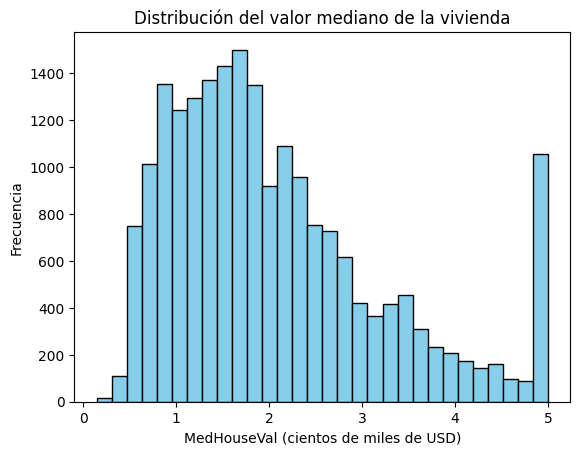

In [6]:
fig, ax = plt.subplots()
ax.hist(df_california["MedHouseVal"], bins=30, color="skyblue", edgecolor="black")
ax.set_title("Distribución del valor mediano de la vivienda")
ax.set_xlabel("MedHouseVal (cientos de miles de USD)")
ax.set_ylabel("Frecuencia")
plt.show()

Se observa una acumulación de valores en 5, porque el dataset tiene un tope en ese valor: las viviendas más caras quedaron registradas como 5.

## 5. Relación entre ingreso y valor de la vivienda

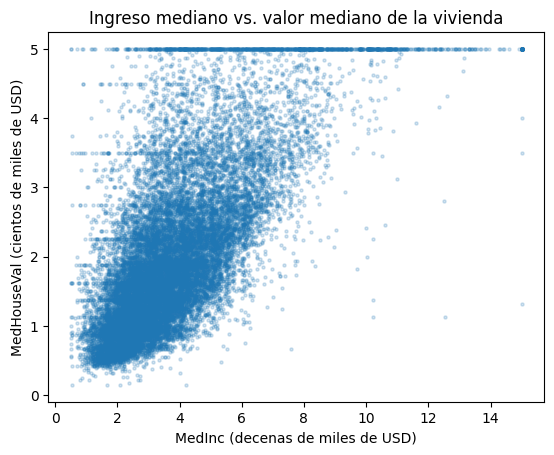

Correlación MedInc - MedHouseVal: 0.69


In [7]:
fig, ax = plt.subplots()
ax.scatter(df_california["MedInc"], df_california["MedHouseVal"], alpha=0.2, s=5)
ax.set_title("Ingreso mediano vs. valor mediano de la vivienda")
ax.set_xlabel("MedInc (decenas de miles de USD)")
ax.set_ylabel("MedHouseVal (cientos de miles de USD)")
plt.show()

print("Correlación MedInc - MedHouseVal:", round(df_california["MedInc"].corr(df_california["MedHouseVal"]), 2))

Hay una relación positiva: en las zonas con mayor ingreso, las viviendas tienden a valer más. Es la variable más relacionada con el precio.

## Conclusión
El dataset está completo y listo para usar. Para la app se eligieron como filtros la edad de las casas (`HouseAge`) y la latitud, y como gráficos el histograma del valor y la dispersión ingreso-valor.